# Data Visualization with Matplotlib & Seaborn
**Project 02 | Data Science & AI | InternCircle**

Dataset: seaborn's built-in `tips` dataset (244 restaurant meals: total bill, tip, day, time, size, smoker).

The plotting functions live in `visualize_tips.py`; this notebook walks through the project step by step.

## Step 1: Choose the questions
1. How are bills distributed?
2. Do tips differ by day?
3. Does a bigger bill mean a bigger tip?
4. Which numbers move together?

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import visualize_tips as vt

%matplotlib inline
tips = vt.load_data()
takeaways = vt.compute_takeaways(tips)
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


In [2]:
tips.info()
tips.describe()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
 7   tip_pct     244 non-null    float64 
dtypes: category(4), float64(3), int64(1)
memory usage: 9.3 KB


,total_bill,tip,size,tip_pct
count,244.000000,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672,16.080258
std,8.902412,1.383638,0.951100,6.107220
min,3.070000,1.000000,1.000000,3.563814
25%,13.347500,2.000000,2.000000,12.912736
50%,17.795000,2.900000,2.000000,15.476977
75%,24.127500,3.562500,3.000000,19.147549
max,50.810000,10.000000,6.000000,71.034483


## Step 2: Match charts to questions
| Question | Chart | Why |
|---|---|---|
| Q1 distribution of one number | Histogram | shows shape and spread |
| Q2 compare groups | Box plot (+ bar chart) | shows median, spread, outliers per day |
| Q3 two numbers | Scatter plot | shows the relationship, colour = time of day |
| Q4 correlations | Heatmap | all pairs at once |

## Steps 3-4: Draw the charts and use colour carefully
One colour-blind-friendly palette (blue/orange/sky blue), no red + green. Colour means *time of day* in the scatter plot; elsewhere a single colour is used so colour is never decoration.

### Q1. How are bills distributed?

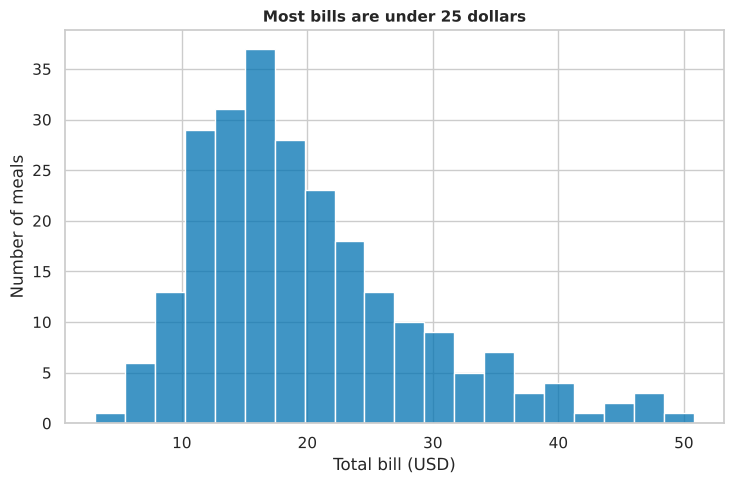

Takeaway: 70% of bills are between $10 and $25; the median bill is $17.80 and a few large bills stretch the right tail.


In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5))
vt.plot_histogram(tips, ax)
plt.tight_layout(); plt.show()
print('Takeaway:', takeaways['hist'])

### Q2. Do tips differ by day?

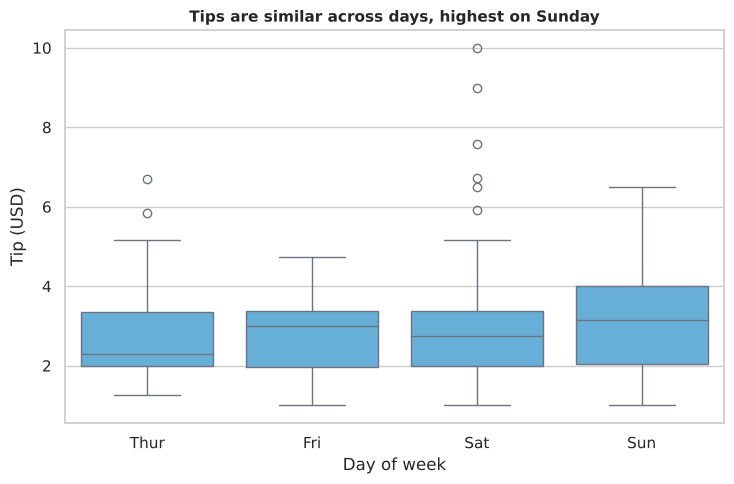

Takeaway: Sunday tips are highest (average $3.26) and Friday the lowest ($2.73), but the boxes overlap heavily.


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 5))
vt.plot_boxplot(tips, ax)
plt.tight_layout(); plt.show()
print('Takeaway:', takeaways['box'])

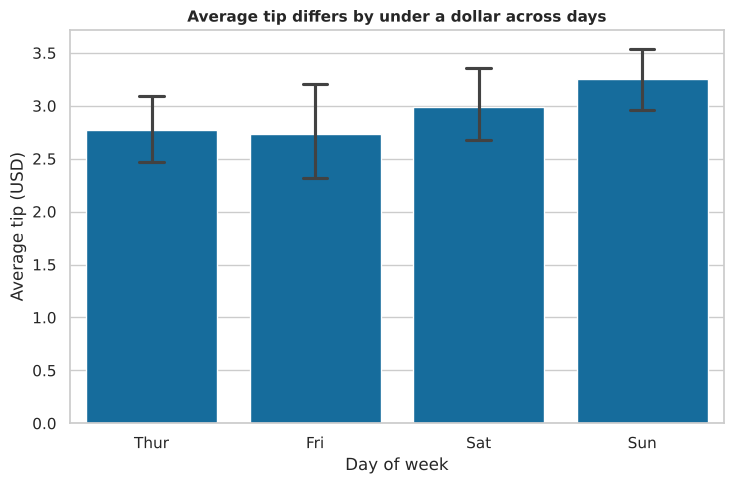

Takeaway: Average tip per meal ranges from $2.73 to $3.26 across days, a gap of $0.52.


In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5))
vt.plot_bar(tips, ax)   # y-axis starts at zero; error bars = 95% CI
plt.tight_layout(); plt.show()
print('Takeaway:', takeaways['bar'])

### Q3. Does a bigger bill mean a bigger tip?

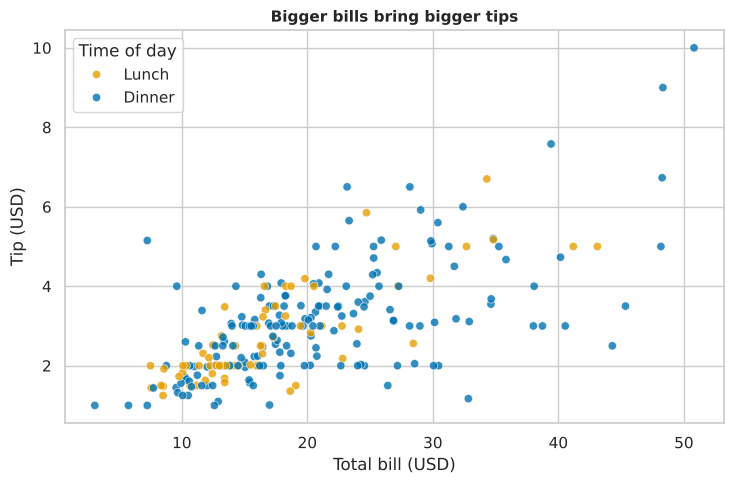

Takeaway: Tips rise with the bill (r = 0.68); dinner tips average $3.10 against $2.73 at lunch.


In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5))
vt.plot_scatter(tips, ax)
plt.tight_layout(); plt.show()
print('Takeaway:', takeaways['scatter'])

## Step 5: Correlation heatmap
### Q4. Which numbers move together?

In [7]:
tips[['total_bill', 'tip', 'size']].corr().round(2)

,total_bill,tip,size
total_bill,1.00,0.68,0.60
tip,0.68,1.00,0.49
size,0.60,0.49,1.00


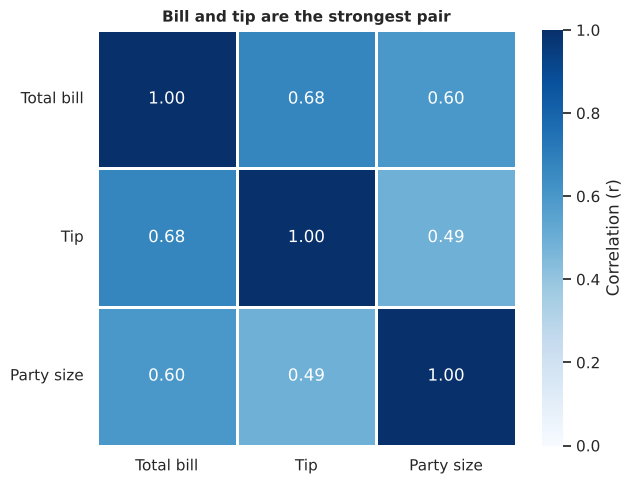

Takeaway: The strongest relationship is total bill and tip (r = 0.68); party size is only moderately linked to either.


In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5))
vt.plot_heatmap(tips, ax)
plt.tight_layout(); plt.show()
print('Takeaway:', takeaways['heatmap'])

## Steps 6-7: Combine into a dashboard image and write the takeaways
Four charts in a 2 x 2 grid, saved at 150 dpi with a one-line takeaway under each chart.

In [9]:
vt.OUT_DIR.mkdir(exist_ok=True)
vt.save_individual_charts(tips, takeaways)
vt.save_dashboard(tips, takeaways)
vt.write_takeaways(takeaways)

saved charts/01_bill_distribution.png
saved charts/02_tips_by_day_boxplot.png


saved charts/03_bill_vs_tip_scatter.png
saved charts/04_correlation_heatmap.png


saved charts/05_average_tip_by_day_bar.png


saved charts/tips_overview.png
saved takeaways.md


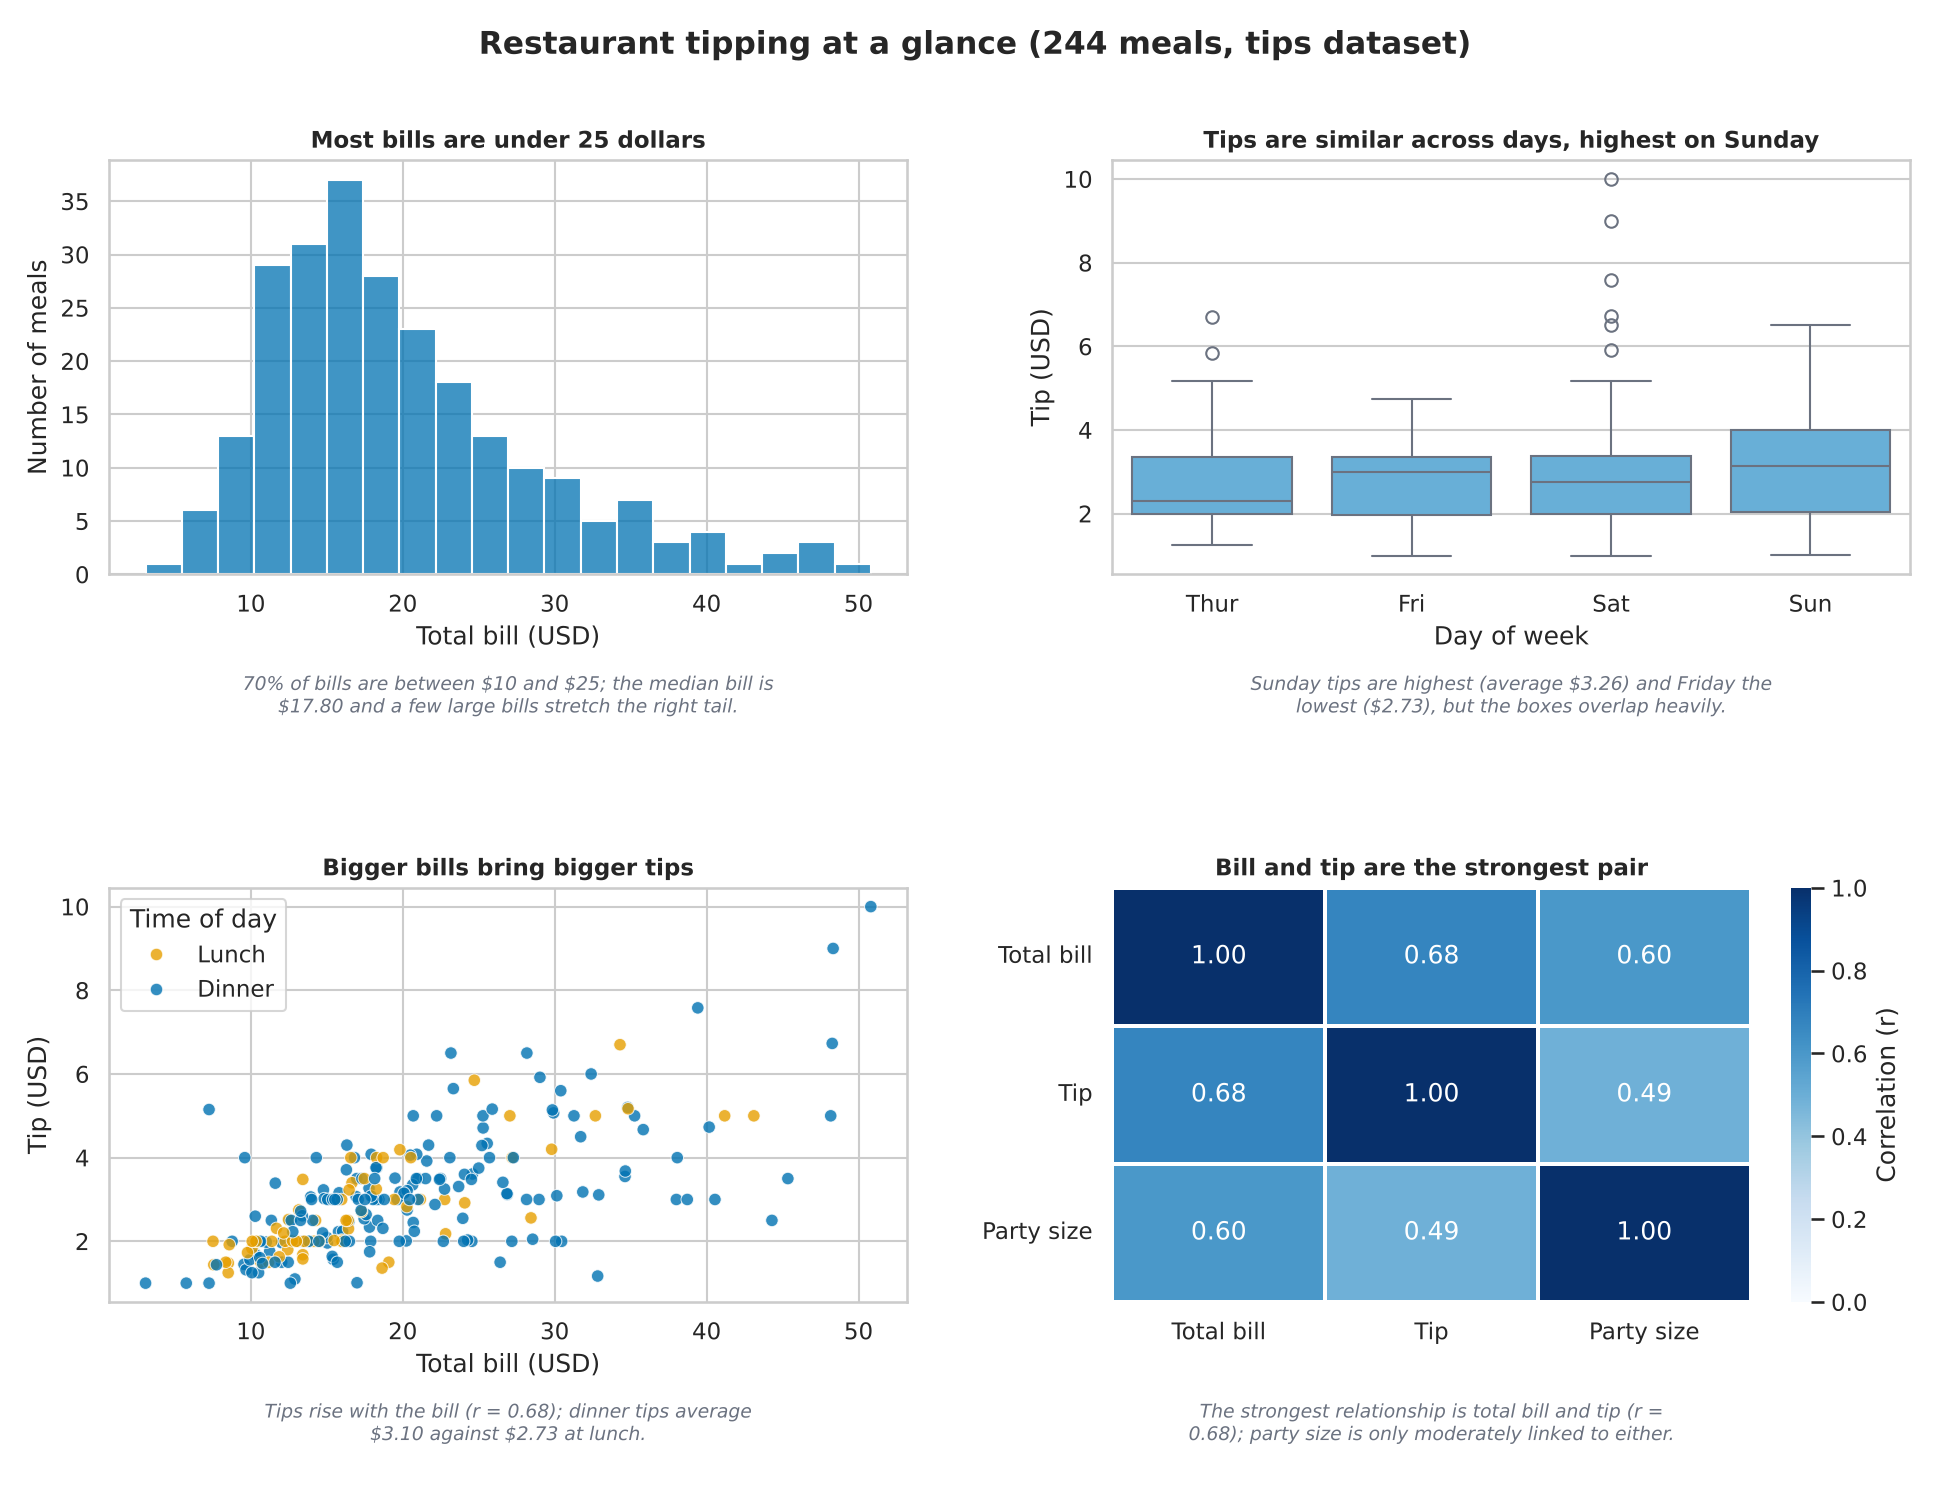

In [10]:
from IPython.display import Image
Image(filename='charts/tips_overview.png')

## Step 8: Review for honesty
- Bar chart y-axis starts at **0**; no truncated axes.
- `tight_layout()` used, so no labels are cut off.
- Titles state the finding; every axis has a label and unit (USD).
- Palette is colour-blind friendly (no red/green pairing).
- Correlation is not causation: bigger parties spend more, which drives bigger tips.
- Friday has only 19 meals, so its average is less reliable than Saturday's (87).